# Attribute By Attribute: Which Generalised Predictor Changes The Scores?

The anonymised release differs from the source release in eight generalised predictors: `Age_Band`, `Gender`, `State`, `Occupation`, `Property_Type`, `Number_Of_Bedrooms`, `Number_Of_Occupants` and `Property_Valuation_AUD`. The earlier audits replaced all eight at once and found that the mean difference between the releases is smaller than the variation between splits.

This notebook splits that block. In every experiment only one of the eight predictors takes its anonymised value and the other seven keep their source values, so the notebook shows whether any single attribute carries an anonymisation cost that is hidden in the combined comparison.

## Worked Example

The table shows the eight predictors of one household in the four kinds of tables that are built. The values are illustrative and a real row is printed further below.

| Predictor | `baseline` | `only State` | `only Occupation` | `all eight` |
|---|---|---|---|---|
| Age_Band | 25-34 | 25-34 | 25-34 | 18-34 |
| Gender | Male | Male | Male | Male |
| State | VIC | **East Coast** | VIC | East Coast |
| Occupation | Bookkeeper | Bookkeeper | **Business & Technology** | Business & Technology |
| Property_Type | villa | villa | villa | attached |
| Number_Of_Bedrooms | 4 | 4 | 4 | 4 |
| Number_Of_Occupants | 3 | 3 | 3 | 3 |
| Property_Valuation_AUD | 111,576 | 111,576 | 111,576 | 110,000 |

- `baseline` holds the source value of every predictor. It is the starting point of every comparison and equals the source release in the earlier audits.
- `only State` takes the anonymised value of `State` and the source value of the other seven predictors. The same is done for every other attribute.
- `all eight` takes the anonymised value of all eight predictors. It equals the anonymised release in the earlier audits.

Every table has the same 20 predictors (12 documented-record predictors and the 8 generalised predictors) and the same rows. Only the content of one column changes, and no predictor is removed. The score of `only State` minus the score of `baseline` is the change that comes from anonymising `State` alone.

## Design

- **Question.** Does any single generalised predictor carry an anonymisation cost that can be separated from the variation between splits?
- **Feature set.** Rung B of the feature ladder of notebooks 02 and 03: the 12 documented-record predictors plus the 8 generalised predictors (20 in total), with the columns in the order of the modelling table. The 12 documented-record predictors are identical in both releases.
- **Tables.** The `baseline` table (all eight predictors from the source release), eight tables in which one predictor takes the anonymised value, and the `all eight` table. The tables are built from the two modelling tables, which have the same rows in the same order.
- **Splits.** The same as in the earlier audits. For each of the 50 seeds (1 to 51, without 42) the table is partitioned by two successive grouped shuffle splits by `Customer_ID` (70% train, then the remainder halved into validation and test) using the source customer labels, and the same partitions are applied to all tables. The validation partition is not used.
- **Models.** The Random Forest, the Logistic Regression and CatBoost with the same fixed settings as in the earlier audits, with no search, no tuning and no selection. The preprocessing is fitted on the training partition only.
- **Scoring.** Both scorings of notebook 03 are computed from the same fit. "All categories" is the scoring of the earlier audits, and "candidates only" removes the categories that the household has already recorded before the ranking is scored.
- **Comparison.** For every split, the score of a table minus the score of `baseline` (paired within the split).
- **Descriptive only.** The 50 splits overlap and come from the same 431 states, so the spread is not the sampling variability of a new set of customers, and no significance statement is made. The differences of single attributes are not additive, because the attributes are related to each other.
- **Nothing is saved.** No file is written.

## Setup

The notebook reads the model state tables of the two releases. The paths are relative to this notebook and follow the folder layout of the repository.

In [1]:
# -------------------------------------------------------------------
# Setup
# -------------------------------------------------------------------
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path("../../../data/processed/hypothesis_testing")

SEEDS = [seed for seed in range(1, 52) if seed != 42]
CHECK_SEED = 42

# Number of splits used by each model. Lower the value of the slowest model (CatBoost) to shorten the run.
N_SPLITS = {"random_forest": 50, "logistic": 50, "catboost": 50}

for path in [DATA_DIR / "source_dataset" / "model_state.csv", DATA_DIR / "regions_anonymised" / "model_state.csv"]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

## Data

Both modelling tables have the same rows in the same order. The keys, the prediction times and the targets are checked to be equal, and the columns that differ between the two tables are listed. They must be the eight generalised predictors and the pseudonymised `Customer_ID`.

In [2]:
source = pd.read_csv(DATA_DIR / "source_dataset" / "model_state.csv", parse_dates=["Prediction_Time"])
regions = pd.read_csv(DATA_DIR / "regions_anonymised" / "model_state.csv", parse_dates=["Prediction_Time"])

assert list(source.columns) == list(regions.columns), "the two tables must have the same columns"
for column in ["Property_ID", "Prediction_Time", "Next_Category"]:
    assert (source[column].values == regions[column].values).all(), column

GENERALISED_FEATURES = [
    "Age_Band", "Gender", "State", "Occupation",
    "Property_Type", "Number_Of_Bedrooms", "Number_Of_Occupants", "Property_Valuation_AUD",
]

different_columns = [column for column in source.columns if not source[column].equals(regions[column])]

print("DATA LOADED")
print("-" * 60)
print(f"Rows:       {len(source):,}")
print(f"Properties: {source['Property_ID'].nunique():,}")
print(f"Customers:  {source['Customer_ID'].nunique():,}")
print()
print("Columns that differ between the two releases:")
print(different_columns)

assert set(different_columns) == set(GENERALISED_FEATURES) | {"Customer_ID"}, "unexpected difference between the releases"

DATA LOADED
------------------------------------------------------------
Rows:       431
Properties: 234
Customers:  198

Columns that differ between the two releases:
['Customer_ID', 'Property_Type', 'Number_Of_Occupants', 'Number_Of_Bedrooms', 'Property_Valuation_AUD', 'Age_Band', 'Gender', 'State', 'Occupation']


## Recorded Categories

For the scoring "candidates only", the categories that a household has already recorded are read from the documented category counts of the modelling table. The same checks as in notebook 03 are made, except the comparison with the asset table of the workbook.

In [3]:
# -------------------------------------------------------------------
# Recorded Categories R(t)
# -------------------------------------------------------------------
CATEGORY_IDS = [f"CAT-00{number}" for number in range(1, 8)]

CLASSES = sorted(source["Next_Category"].unique())
CLASS_INDEX = {label: position for position, label in enumerate(CLASSES)}

# The category name of every identifier, taken from the target columns of the modelling table.
NAME_OF_ID = source.drop_duplicates("Next_Category_ID").set_index("Next_Category_ID")["Next_Category"].to_dict()
ID_OF_CLASS = {name: category_id for category_id, name in NAME_OF_ID.items()}
assert set(CATEGORY_IDS) == set(NAME_OF_ID), "a category identifier is missing in the target columns"

# Recorded categories as a table of rows by classes, in the order of CLASSES.
RECORDED = np.column_stack([(source[f"documented_count_{ID_OF_CLASS[label]}"].values > 0) for label in CLASSES])

all_recorded = np.column_stack([(source[f"documented_count_{category_id}"].values > 0) for category_id in CATEGORY_IDS])
size_ok = (all_recorded.sum(axis=1) == source["documented_category_count"].values)

target_position = source["Next_Category"].map(CLASS_INDEX).values
target_recorded = RECORDED[np.arange(len(source)), target_position]

print("RECORDED CATEGORIES")
print("-" * 80)
print(f"Categories that occur as a target: {len(CLASSES)} of {len(CATEGORY_IDS)}")
print(f"States where |R(t)| equals documented_category_count: {int(size_ok.sum())} of {len(source)}")
print(f"States whose target is already in R(t):                {int(target_recorded.sum())} of {len(source)}")

assert size_ok.all(), "R(t) does not match documented_category_count"
assert not target_recorded.any(), "a target is already recorded"

RECORDED CATEGORIES
--------------------------------------------------------------------------------
Categories that occur as a target: 7 of 7
States where |R(t)| equals documented_category_count: 431 of 431
States whose target is already in R(t):                0 of 431


## Feature Set And Tables

The feature set is rung B of the earlier audits, with the columns in the order of the modelling table. The ten tables are built from the source table by replacing one column, or all eight, by the column of the anonymised release. The checks make sure that exactly the intended columns were replaced and that the split of the columns into numeric and categorical predictors does not change, because the preprocessing treats the two kinds differently.

In [4]:
# -------------------------------------------------------------------
# Feature Set Of Rung B
# -------------------------------------------------------------------
IDENTIFIERS = ["Property_ID", "Customer_ID", "Prediction_Time", "Next_Category_ID", "Next_Category"]
ALL_FEATURES = [column for column in source.columns if column not in IDENTIFIERS]

RECORD_FEATURES = [
    "documented_asset_count",
    "documented_category_count",
    "documented_value_total",
    "documented_replacement_cost_total",
    "mean_evidence_rating",
] + [f"documented_count_CAT-00{number}" for number in range(1, 8)]

B_COLUMNS = [column for column in ALL_FEATURES if column in set(RECORD_FEATURES + GENERALISED_FEATURES)]

assert len(RECORD_FEATURES) == 12 and len(GENERALISED_FEATURES) == 8
assert len(B_COLUMNS) == 20 and len(set(B_COLUMNS)) == 20

for column in RECORD_FEATURES:
    assert source[column].equals(regions[column]), f"{column} differs between the releases"


# -------------------------------------------------------------------
# The Ten Tables
# -------------------------------------------------------------------
def with_regions_values(columns):
    """The source table with the listed columns replaced by the anonymised values."""
    table = source.copy()
    for column in columns:
        table[column] = regions[column].values
    return table


VARIANTS = {"baseline": with_regions_values([])}
for attribute in GENERALISED_FEATURES:
    VARIANTS[f"only {attribute}"] = with_regions_values([attribute])
VARIANTS["all eight"] = with_regions_values(GENERALISED_FEATURES)

REPLACED = {"baseline": []}
REPLACED.update({f"only {attribute}": [attribute] for attribute in GENERALISED_FEATURES})
REPLACED["all eight"] = GENERALISED_FEATURES

# Check 1: only the intended columns hold anonymised values, and every other column equals the source column.
for name, table in VARIANTS.items():
    for column in B_COLUMNS:
        reference = regions[column] if column in REPLACED[name] else source[column]
        assert table[column].equals(reference), (name, column)

# Check 2: the split of the columns into numeric and categorical predictors is the same in all tables.
def column_kinds(table):
    numeric = table[B_COLUMNS].select_dtypes(include=["number"]).columns.tolist()
    return numeric, [column for column in B_COLUMNS if column not in numeric]

kinds_of_baseline = column_kinds(VARIANTS["baseline"])
for name, table in VARIANTS.items():
    assert column_kinds(table) == kinds_of_baseline, name

print("FEATURE SET OF RUNG B AND THE TEN TABLES")
print("-" * 80)
print(f"Predictors:             {len(B_COLUMNS)} ({len(RECORD_FEATURES)} documented-record, {len(GENERALISED_FEATURES)} generalised)")
print(f"Numeric / categorical:  {len(kinds_of_baseline[0])} / {len(kinds_of_baseline[1])}")
print(f"Tables:                 {len(VARIANTS)}")
print()
print("Number of distinct values per generalised predictor (source -> anonymised)")
for attribute in GENERALISED_FEATURES:
    print(f"  {attribute:<24} {source[attribute].nunique():>4} -> {regions[attribute].nunique():>4}   dtype {source[attribute].dtype} -> {regions[attribute].dtype}")

FEATURE SET OF RUNG B AND THE TEN TABLES
--------------------------------------------------------------------------------
Predictors:             20 (12 documented-record, 8 generalised)
Numeric / categorical:  15 / 5
Tables:                 10

Number of distinct values per generalised predictor (source -> anonymised)
  Age_Band                    6 ->    4   dtype object -> object
  Gender                      3 ->    4   dtype object -> object
  State                       8 ->    4   dtype object -> object
  Occupation                 32 ->    5   dtype object -> object
  Property_Type               6 ->    5   dtype object -> object
  Number_Of_Bedrooms          8 ->    4   dtype int64 -> float64
  Number_Of_Occupants         7 ->    6   dtype int64 -> int64
  Property_Valuation_AUD    233 ->   23   dtype int64 -> int64


## Example Row

One real row in which `State` and `Occupation` differ between the two releases is shown for the four kinds of tables of the worked example above.

In [5]:
# -------------------------------------------------------------------
# Example Row
# -------------------------------------------------------------------
changed = np.where((source["State"] != regions["State"]) & (source["Occupation"] != regions["Occupation"]))[0]
row = int(changed[0]) if len(changed) else 0

example = pd.DataFrame(
    {name: VARIANTS[name].loc[row, GENERALISED_FEATURES] for name in ["baseline", "only State", "only Occupation", "all eight"]}
)

print("EXAMPLE ROW")
print("-" * 80)
print(f"Row {row}, property {source.loc[row, 'Property_ID']}")
print(example.to_string())

EXAMPLE ROW
--------------------------------------------------------------------------------
Row 0, property PRP-000004
                          baseline  only State        only Occupation              all eight
Age_Band                     25-34       25-34                  25-34                  18-34
Gender                        Male        Male                   Male                   Male
State                          VIC  East Coast                    VIC             East Coast
Occupation              Bookkeeper  Bookkeeper  Business & Technology  Business & Technology
Property_Type                villa       villa                  villa               attached
Number_Of_Bedrooms               4           4                      4                    4.0
Number_Of_Occupants              3           3                      3                      3
Property_Valuation_AUD      111576      111576                 111576                 110000


## Models And Scoring

The models, the preprocessing and the split function of notebook 03. Both scorings are computed from the same fitted model. In the scoring "all categories" the predicted class and the ranked probabilities are used as in the earlier audits. In the scoring "candidates only" the probability of every recorded category is replaced by a value below every probability before the ranking, so that these categories rank last and are not part of the scored list.

In [6]:
# -------------------------------------------------------------------
# Models
# -------------------------------------------------------------------
FOREST_SETTINGS = dict(n_estimators=500, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
LOGISTIC_SETTINGS = dict(max_iter=5000, random_state=42)
CATBOOST_SETTINGS = dict(
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=-1,
)

MODELS = {
    "random_forest": (RandomForestClassifier, FOREST_SETTINGS),
    "logistic": (LogisticRegression, LOGISTIC_SETTINGS),
    "catboost": (CatBoostClassifier, CATBOOST_SETTINGS),
}
MODEL_LABELS = {"random_forest": "Random Forest", "logistic": "Logistic Regression", "catboost": "CatBoost"}


# -------------------------------------------------------------------
# Functions
# -------------------------------------------------------------------
def build_pipeline(frame, columns, model_name="random_forest"):
    numeric = frame[columns].select_dtypes(include=["number"]).columns.tolist()
    categorical = [column for column in columns if column not in numeric]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numerical",
                Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                numeric,
            ),
            (
                "categorical",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]),
                categorical,
            ),
        ]
    )

    classifier_class, settings = MODELS[model_name]
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier_class(**settings))])


def customer_grouped_split(seed):
    groups = source["Customer_ID"]
    target = source["Next_Category"]

    train_idx, temp_idx = next(
        GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=seed).split(source, target, groups=groups)
    )
    val_rel, test_rel = next(
        GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=seed).split(
            source.iloc[temp_idx], target.iloc[temp_idx], groups=groups.iloc[temp_idx]
        )
    )
    return train_idx, temp_idx[val_rel], temp_idx[test_rel]


def scores(y_true, predictions, ranked):
    """Top-1 accuracy and F1 from the predicted class, Top-2 and Top-3 from the ranked classes."""
    return dict(
        top1_accuracy=accuracy_score(y_true, predictions),
        macro_f1=f1_score(y_true, predictions, average="macro", zero_division=0),
        weighted_f1=f1_score(y_true, predictions, average="weighted", zero_division=0),
        top2_accuracy=float(np.mean([truth in row[:2] for truth, row in zip(y_true, ranked)])),
        top3_accuracy=float(np.mean([truth in row[:3] for truth, row in zip(y_true, ranked)])),
    )


def evaluate(variant, train_idx, test_idx, model_name="random_forest"):
    frame = VARIANTS[variant]
    X_train, X_test = frame[B_COLUMNS].iloc[train_idx], frame[B_COLUMNS].iloc[test_idx]
    y_train, y_test = frame["Next_Category"].iloc[train_idx], frame["Next_Category"].iloc[test_idx]

    model = build_pipeline(frame, B_COLUMNS, model_name).fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)
    classes = np.asarray(model.named_steps["classifier"].classes_)
    recorded = RECORDED[test_idx][:, [CLASS_INDEX[label] for label in classes]]

    # Scoring "all categories", as in the earlier notebooks.
    order_all = np.argsort(-probabilities, axis=1, kind="stable")
    result_all = scores(y_test.values, np.asarray(model.predict(X_test)).ravel(), classes[order_all])

    # Scoring "candidates only": the recorded categories rank last.
    order_candidates = np.argsort(-np.where(recorded, -1.0, probabilities), axis=1, kind="stable")
    ranked_candidates = classes[order_candidates]
    result_candidates = scores(y_test.values, ranked_candidates[:, 0], ranked_candidates)

    return result_all, result_candidates

## One Split As A Check

Before the repetitions, the Random Forest is fitted on the ten tables for the seed that the earlier notebooks use as the reference split (seed 42). The table shows that the notebook runs end to end and gives a first impression of the size of the differences. It is a single split and not a result. The comparison with the earlier audits follows after the repetitions.

In [7]:
train_idx, val_idx, test_idx = customer_grouped_split(CHECK_SEED)

print(f"ONE SPLIT (SEED {CHECK_SEED}, RANDOM FOREST, SCORING ALL CATEGORIES)")
print("-" * 80)
print(f"Train {len(train_idx)} rows | test {len(test_idx)} rows | customers shared by train and test: "
      f"{len(set(source['Customer_ID'].iloc[train_idx]) & set(source['Customer_ID'].iloc[test_idx]))}")
print()

rows = []
for name in VARIANTS:
    result_all, result_candidates = evaluate(name, train_idx, test_idx, "random_forest")
    rows.append(dict(table=name, top1=result_all["top1_accuracy"], top2=result_all["top2_accuracy"], top3=result_all["top3_accuracy"], macro_f1=result_all["macro_f1"]))

check = pd.DataFrame(rows).set_index("table")
print(check.round(4).to_string())

ONE SPLIT (SEED 42, RANDOM FOREST, SCORING ALL CATEGORIES)
--------------------------------------------------------------------------------
Train 315 rows | test 59 rows | customers shared by train and test: 0

                               top1    top2    top3  macro_f1
table                                                        
baseline                     0.5254  0.6949  0.8475    0.3914
only Age_Band                0.5085  0.7458  0.8814    0.3535
only Gender                  0.5085  0.7119  0.8814    0.3853
only State                   0.4915  0.6780  0.8136    0.3652
only Occupation              0.5085  0.7458  0.8644    0.3532
only Property_Type           0.5085  0.6949  0.8475    0.3788
only Number_Of_Bedrooms      0.5254  0.6949  0.8814    0.3929
only Number_Of_Occupants     0.5254  0.6949  0.8644    0.3914
only Property_Valuation_AUD  0.5085  0.6949  0.8644    0.3733
all eight                    0.4915  0.7458  0.8644    0.3432


## Repeated Splits

For each seed the three models are refitted on the training partition of every one of the ten tables and scored on the test partition, in both scorings. The tables of one seed use the same partitions. The results are kept in memory only. The Random Forest and the Logistic Regression are fast, CatBoost needs the most time.

In [8]:
records = []


def run_model(model_name):
    started = time.time()
    seeds = SEEDS[: N_SPLITS[model_name]]

    for number, seed in enumerate(seeds, start=1):
        train_idx, val_idx, test_idx = customer_grouped_split(seed)

        for variant in VARIANTS:
            result_all, result_candidates = evaluate(variant, train_idx, test_idx, model_name)
            common = dict(seed=seed, model=model_name, variant=variant, test_rows=len(test_idx))
            records.append(dict(scoring="A: all categories", **common, **result_all))
            records.append(dict(scoring="B: candidates only", **common, **result_candidates))

        if number % 10 == 0:
            print(f"{MODEL_LABELS[model_name]}: {number} of {len(seeds)} splits done ({(time.time() - started) / 60:.1f} min)")

    print(f"{MODEL_LABELS[model_name]} finished: {len(seeds)} splits in {(time.time() - started) / 60:.1f} min")

In [9]:
run_model("random_forest")

Random Forest: 10 of 50 splits done (1.6 min)
Random Forest: 20 of 50 splits done (3.3 min)
Random Forest: 30 of 50 splits done (5.0 min)
Random Forest: 40 of 50 splits done (6.7 min)
Random Forest: 50 of 50 splits done (8.1 min)
Random Forest finished: 50 splits in 8.1 min


In [10]:
run_model("logistic")

Logistic Regression: 10 of 50 splits done (0.1 min)
Logistic Regression: 20 of 50 splits done (0.1 min)
Logistic Regression: 30 of 50 splits done (0.1 min)
Logistic Regression: 40 of 50 splits done (0.2 min)
Logistic Regression: 50 of 50 splits done (0.2 min)
Logistic Regression finished: 50 splits in 0.2 min


In [11]:
run_model("catboost")

CatBoost: 10 of 50 splits done (6.9 min)
CatBoost: 20 of 50 splits done (13.7 min)
CatBoost: 30 of 50 splits done (20.5 min)
CatBoost: 40 of 50 splits done (27.4 min)
CatBoost: 50 of 50 splits done (34.2 min)
CatBoost finished: 50 splits in 34.2 min


## Spread Of Each Table

Mean and standard deviation over the splits for every table, model and scoring. The standard deviation is the variation between splits of one table. The two end points `baseline` and `all eight` are the rung B cells of the earlier audits.

In [12]:
per_split = pd.DataFrame(records)
METRICS = {
    "top1_accuracy": "Top-1",
    "top2_accuracy": "Top-2",
    "top3_accuracy": "Top-3",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
}
SCORINGS = ["A: all categories", "B: candidates only"]
VARIANT_NAMES = list(VARIANTS)

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    group = per_split[per_split["model"] == model_name]
    print("=" * 110)
    print(f"{MODEL_LABELS[model_name]}: {group['seed'].nunique()} splits")
    print("=" * 110)

    table = []
    for scoring in SCORINGS:
        for variant in VARIANT_NAMES:
            part = group[(group["scoring"] == scoring) & (group["variant"] == variant)]
            row = {"scoring": scoring, "table": variant}
            for column, label in METRICS.items():
                row[label] = f"{part[column].mean():.4f} ({part[column].std():.4f})"
            table.append(row)
    print("mean (standard deviation) over the splits")
    print(pd.DataFrame(table).to_string(index=False))
    print()

Random Forest: 50 splits
mean (standard deviation) over the splits
           scoring                       table           Top-1           Top-2           Top-3        Macro F1     Weighted F1
 A: all categories                    baseline 0.4626 (0.0548) 0.7403 (0.0452) 0.8639 (0.0362) 0.3709 (0.0638) 0.4278 (0.0540)
 A: all categories               only Age_Band 0.4629 (0.0493) 0.7440 (0.0472) 0.8641 (0.0411) 0.3735 (0.0605) 0.4304 (0.0502)
 A: all categories                 only Gender 0.4679 (0.0531) 0.7417 (0.0503) 0.8667 (0.0414) 0.3749 (0.0636) 0.4318 (0.0520)
 A: all categories                  only State 0.4709 (0.0459) 0.7449 (0.0498) 0.8634 (0.0378) 0.3794 (0.0644) 0.4370 (0.0476)
 A: all categories             only Occupation 0.4678 (0.0545) 0.7419 (0.0481) 0.8607 (0.0324) 0.3774 (0.0723) 0.4360 (0.0553)
 A: all categories          only Property_Type 0.4625 (0.0464) 0.7461 (0.0483) 0.8664 (0.0420) 0.3693 (0.0612) 0.4273 (0.0457)
 A: all categories     only Number_Of_Bedroo

## Reproduction Check Against Notebook 03

The two end points must equal the rung B cells of notebook 03 in the scoring "all categories": `baseline` is the source release and `all eight` is the anonymised release. The reference values are the means over the 50 splits of notebook 03. The check is made only when all 50 splits were run, and a difference in the fourth decimal of CatBoost can come from multithreading.

In [13]:
# Means over 50 splits of rung B in notebook 03, scoring "all categories": Top-1, Top-2, Top-3, Macro F1.
REFERENCE_03 = {
    ("random_forest", "baseline"): (0.4626, 0.7403, 0.8639, 0.3709),
    ("random_forest", "all eight"): (0.4599, 0.7404, 0.8564, 0.3720),
    ("logistic", "baseline"): (0.3520, 0.6308, 0.8075, 0.3003),
    ("logistic", "all eight"): (0.3774, 0.6678, 0.8317, 0.3173),
    ("catboost", "baseline"): (0.4568, 0.7626, 0.9003, 0.3824),
    ("catboost", "all eight"): (0.4531, 0.7573, 0.8891, 0.3813),
}
COLUMNS_03 = ["top1_accuracy", "top2_accuracy", "top3_accuracy", "macro_f1"]

print("REPRODUCTION OF RUNG B OF NOTEBOOK 03 (SCORING: ALL CATEGORIES)")
print("-" * 100)

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    group = per_split[(per_split["model"] == model_name) & (per_split["scoring"] == SCORINGS[0])]
    if group["seed"].nunique() < 50:
        print(f"{MODEL_LABELS[model_name]}: fewer than 50 splits, check skipped")
        continue
    for variant in ["baseline", "all eight"]:
        mean = group[group["variant"] == variant][COLUMNS_03].mean().round(4).tolist()
        expected = list(REFERENCE_03[(model_name, variant)])
        largest = max(abs(a - b) for a, b in zip(mean, expected))
        print(f"{MODEL_LABELS[model_name]:<20} {variant:<10} largest difference to notebook 03: {largest:.4f}   equal: {largest < 5e-5}")

REPRODUCTION OF RUNG B OF NOTEBOOK 03 (SCORING: ALL CATEGORIES)
----------------------------------------------------------------------------------------------------
Random Forest        baseline   largest difference to notebook 03: 0.0000   equal: True
Random Forest        all eight  largest difference to notebook 03: 0.0000   equal: True
Logistic Regression  baseline   largest difference to notebook 03: 0.0000   equal: True
Logistic Regression  all eight  largest difference to notebook 03: 0.0000   equal: True
CatBoost             baseline   largest difference to notebook 03: 0.0000   equal: True
CatBoost             all eight  largest difference to notebook 03: 0.0000   equal: True


## Effect Of Each Attribute

For every split, the score of a table minus the score of `baseline`, paired within the split. The row `all eight` is the combined effect that the earlier audits measured. `below_zero` is the share of splits in which the difference is negative, and `zero` is the share of splits with no difference.

In [14]:
def describe(values):
    values = np.asarray(values, dtype=float)
    return dict(
        mean=values.mean(),
        sd=values.std(ddof=1) if len(values) > 1 else np.nan,
        p2_5=np.percentile(values, 2.5),
        p97_5=np.percentile(values, 97.5),
        below_zero=(values < 0).mean(),
        zero=(values == 0).mean(),
    )


def wide(model_name, column):
    part = per_split[per_split["model"] == model_name]
    return part.pivot_table(index="seed", columns=["scoring", "variant"], values=column)


def format_table(rows):
    frame = pd.DataFrame(rows)
    for column in ["mean", "sd", "p2_5", "p97_5"]:
        frame[column] = frame[column].map(lambda value: f"{value:+.4f}")
    for column in ["below_zero", "zero"]:
        frame[column] = frame[column].map(lambda value: f"{value:.0%}")
    return frame.to_string(index=False)


DIFFERENCES = {}

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    print("=" * 110)
    print(f"{MODEL_LABELS[model_name]}: table minus baseline, paired within each split")
    print("=" * 110)

    rows = []
    for column, label in METRICS.items():
        table = wide(model_name, column)
        for scoring in SCORINGS:
            for variant in VARIANT_NAMES[1:]:
                difference = table[(scoring, variant)] - table[(scoring, "baseline")]
                DIFFERENCES[(model_name, scoring, label, variant)] = difference
                rows.append(dict(metric=label, scoring=scoring[:1], table=variant, **describe(difference)))
    print(format_table(rows))
    print()

Random Forest: table minus baseline, paired within each split
     metric scoring                       table    mean      sd    p2_5   p97_5 below_zero zero
      Top-1       A               only Age_Band +0.0003 +0.0314 -0.0560 +0.0573        44%  20%
      Top-1       A                 only Gender +0.0053 +0.0227 -0.0354 +0.0429        34%  20%
      Top-1       A                  only State +0.0084 +0.0325 -0.0374 +0.0656        36%  14%
      Top-1       A             only Occupation +0.0053 +0.0352 -0.0548 +0.0830        36%  16%
      Top-1       A          only Property_Type -0.0000 +0.0276 -0.0551 +0.0378        36%  28%
      Top-1       A     only Number_Of_Bedrooms -0.0007 +0.0214 -0.0409 +0.0475        40%  34%
      Top-1       A    only Number_Of_Occupants +0.0016 +0.0068 -0.0133 +0.0168         6%  78%
      Top-1       A only Property_Valuation_AUD -0.0030 +0.0239 -0.0530 +0.0393        42%  28%
      Top-1       A                   all eight -0.0026 +0.0421 -0.0916 +0

## Summary And Figure

The summary shows, for the scoring "all categories", the mean and the standard deviation of the paired difference in Top-1 and in Macro F1 for every attribute and model, next to the variation between splits of the `baseline` itself. The figure shows the mean difference in Top-1 with the interval from the 2.5th to the 97.5th percentile of the 50 paired differences. A dot to the left of zero means that the anonymised attribute lowers the score.

SUMMARY (SCORING: ALL CATEGORIES): table minus baseline, mean (standard deviation) of the paired difference
--------------------------------------------------------------------------------------------------------------
                      table Random Forest Top-1 Random Forest Macro F1 Logistic Regression Top-1 Logistic Regression Macro F1   CatBoost Top-1 CatBoost Macro F1
              only Age_Band    +0.0003 (0.0314)       +0.0025 (0.0397)          +0.0073 (0.0341)             -0.0009 (0.0402) +0.0150 (0.0325)  +0.0159 (0.0388)
                only Gender    +0.0053 (0.0227)       +0.0039 (0.0379)          -0.0001 (0.0174)             -0.0021 (0.0206) +0.0019 (0.0293)  +0.0043 (0.0423)
                 only State    +0.0084 (0.0325)       +0.0085 (0.0440)          -0.0000 (0.0340)             -0.0043 (0.0358) -0.0107 (0.0400)  -0.0110 (0.0377)
            only Occupation    +0.0053 (0.0352)       +0.0065 (0.0431)          +0.0138 (0.0465)             +0.0062 (0.0513) +0.0083 (0.

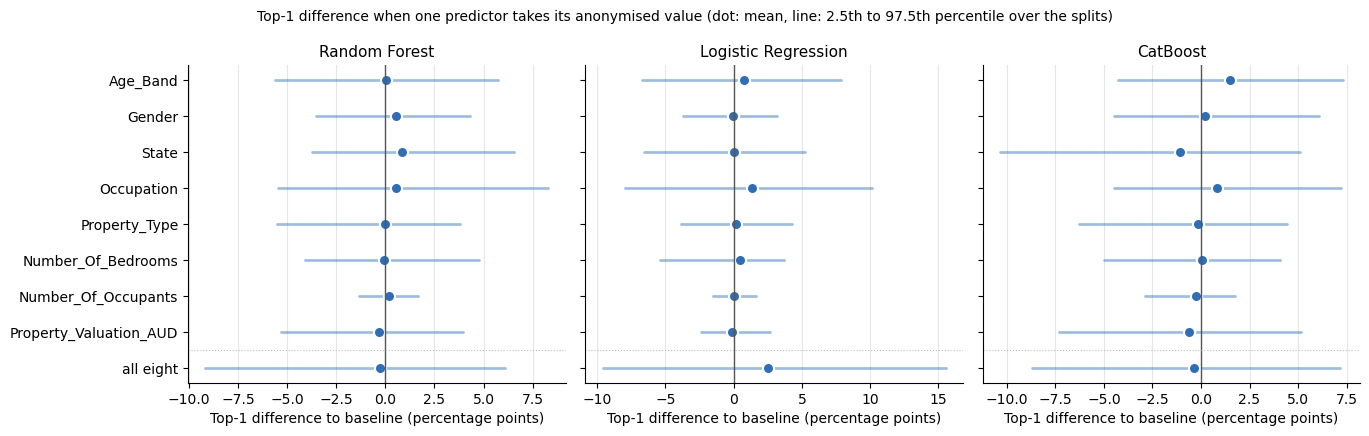

In [15]:
available = [m for m in MODELS if m in set(per_split["model"])]
SCORING_MAIN = SCORINGS[0]

print("SUMMARY (SCORING: ALL CATEGORIES): table minus baseline, mean (standard deviation) of the paired difference")
print("-" * 110)

rows = []
for variant in VARIANT_NAMES[1:]:
    row = {"table": variant}
    for model_name in available:
        top1 = DIFFERENCES[(model_name, SCORING_MAIN, "Top-1", variant)]
        macro = DIFFERENCES[(model_name, SCORING_MAIN, "Macro F1", variant)]
        row[f"{MODEL_LABELS[model_name]} Top-1"] = f"{top1.mean():+.4f} ({top1.std():.4f})"
        row[f"{MODEL_LABELS[model_name]} Macro F1"] = f"{macro.mean():+.4f} ({macro.std():.4f})"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Variation between splits of the baseline (standard deviation of its score)")
for model_name in available:
    part = per_split[(per_split["model"] == model_name) & (per_split["scoring"] == SCORING_MAIN) & (per_split["variant"] == "baseline")]
    print(f"  {MODEL_LABELS[model_name]:<20} Top-1 {part['top1_accuracy'].std():.4f}   Macro F1 {part['macro_f1'].std():.4f}")

# -------------------------------------------------------------------
# Figure
# -------------------------------------------------------------------
BLUE = "#2f6db5"
labels = [name.replace("only ", "") for name in VARIANT_NAMES[1:]]
positions = list(range(len(labels)))[::-1]

figure, axes = plt.subplots(1, len(available), figsize=(4.6 * len(available), 4.4), sharey=True)
axes = np.atleast_1d(axes)

for axis, model_name in zip(axes, available):
    for position, variant in zip(positions, VARIANT_NAMES[1:]):
        values = DIFFERENCES[(model_name, SCORING_MAIN, "Top-1", variant)] * 100
        low, high = np.percentile(values, [2.5, 97.5])
        axis.plot([low, high], [position, position], color=BLUE, linewidth=2, alpha=0.45, solid_capstyle="round")
        axis.plot(values.mean(), position, "o", color=BLUE, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
    axis.axvline(0, color="#555555", linewidth=1)
    axis.axhline(0.5, color="#bbbbbb", linewidth=0.8, linestyle=":")
    axis.set_title(MODEL_LABELS[model_name], fontsize=11)
    axis.set_xlabel("Top-1 difference to baseline (percentage points)")
    axis.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    axis.set_axisbelow(True)
    for side in ["top", "right"]:
        axis.spines[side].set_visible(False)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(labels)
figure.suptitle("Top-1 difference when one predictor takes its anonymised value (dot: mean, line: 2.5th to 97.5th percentile over the splits)", fontsize=10)
figure.tight_layout()
plt.show()

## Limits

- The 50 splits overlap and come from the same 431 states, so the spreads are descriptive and not the sampling variability of a new set of customers. No significance is claimed.
- The differences of the single attributes are not additive. The attributes are related, for example `State` and `Property_Valuation_AUD`, and each difference is measured with the other seven attributes at their source values.
- The static attributes have no timestamp and are assumed to equal their value at the prediction time, as in the earlier audits.
- The models have fixed settings without tuning, so the levels are not comparable with the tuned models. The test partitions have 52 to 83 rows.
- The anonymised values are those of the K3 regions release, and the notebook does not change how the attributes were generalised.

## Results And Interpretation

The reproduction check passed for all three models, so the `baseline` and `all eight` tables of this notebook give the same scores as rung B of notebook 03 and the attribute tables can be compared with the earlier audits. The comparison is descriptive and based on 50 overlapping customer-grouped splits of the same 431 states, so no significance is claimed.

**Size of the differences against the variation between splits.** The score of the `baseline` table varies from split to split with a standard deviation of about 0.05 in Top-1 (0.055 for the Random Forest, 0.050 for the Logistic Regression and 0.053 for CatBoost) and 0.06 to 0.065 in Macro F1. The mean paired difference of a single attribute table against `baseline` is far smaller than this. For the Random Forest it lies between -0.003 and +0.008 in Top-1, for the Logistic Regression between -0.001 and +0.014 and for CatBoost between -0.011 and +0.015, and the paired standard deviation of each difference (0.02 to 0.05 for most attributes) is larger than its mean in every case. The 2.5 to 97.5 percentile range of each single-attribute difference contains zero, and in most tables the difference is below zero in 30% to 45% of the splits. The two scorings give the same picture, so replacing the recorded categories by the lowest rank does not change the conclusion about any single attribute.

**Attributes.** No attribute stands out in all three models. Number_Of_Occupants changes the score least (paired standard deviation about 0.01 or below, with an unchanged score in most splits for the Random Forest and the Logistic Regression), which fits its small change from 7 to 6 values. The largest mean differences are Occupation for the Logistic Regression (+0.014 in Top-1, all categories), Age_Band for CatBoost (+0.015) and State for CatBoost (-0.011), and each of them is smaller than a third of the split-to-split standard deviation and has a sign that is not shared by the other models. The attributes with the strongest generalisation, Occupation (32 to 5 values) and Property_Valuation_AUD (233 to 23 values), do not show a larger or a consistently negative difference than the others.

**All eight together.** For the Random Forest and CatBoost the `all eight` difference is within -0.004 in Top-1 and within -0.015 in Top-3 (Random Forest, candidates only: -0.0146, below zero in 64% of the splits, which is the most consistent sign in the notebook and still small against a split standard deviation of about 0.05). For the Logistic Regression the `all eight` table is higher than `baseline` by +0.025 in Top-1 and +0.037 in Top-2 with the scoring "all categories", and by +0.010 and +0.019 with the scoring "candidates only". The sum of the eight single-attribute means (about +0.026 in Top-1) is close to this value in this model, but the single tables are individually small and the differences between tables are not additive in general, so the single-attribute and the joint results should be read side by side and not added up.

**Reading.** The anonymisation cost is not concentrated in one attribute. Replacing a single predictor by its anonymised form changes the score by less than the variation between splits for every attribute and every model, and the `all eight` table leads to the same conclusion as notebooks 02 and 03 (a difference smaller than the split-to-split variation, with a direction that depends on the model). The result supports the earlier conclusion about the release and does not point to an attribute that should be kept at its source level.

**Limits.** The splits overlap and the 431 states come from a limited number of customers, so the percentile ranges describe the variation between splits and not the sampling error of a new customer set. The models use fixed settings without tuning, and the effect of an attribute can differ when other attributes are present or when the model is tuned for it.